<a href="https://colab.research.google.com/github/vivekpandey0706/Gradient_engine/blob/main/Gradient_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Gradient Descent:
1. compute a loss
2. Ask how that loss would change if each parameter's value changed a bit
3. Nudge every parameter in the direction that lowers this loss


---


This process of finding gradients is called back propagation, available in Pytorch as .backward() function. In this notebook, I implement this using basic Python.

In [15]:
import math
import torch
import random
import matplotlib.pyplot as plt

In [16]:
class Value:
  def __init__ (self, data =0, inputs = (), op = ""):
    self.data = data
    self.grad = 0.0
    self._prev = set(inputs)
    self._op = op
    self._backward = lambda:None

  def __repr__(self):
    return f"Value(data = {self.data})"

  def __add__(self,other):

    if not isinstance(other, Value):
      other = Value(other)

    res = Value(self.data + other.data , (self, other) , "+")

    def _backward():
      self.grad += res.grad
      other.grad += res.grad

    res._backward = _backward
    return res

  def __mul__(self,other):

    if not isinstance(other, Value):
      other = Value(other)

    res = Value((self.data * other.data) , (self,other), "*")

    def _backward():
      self.grad += other.data * res.grad
      other.grad += self.data * res.grad
    res._backward = _backward
    return res


  def __radd__(self, other):
    return self + other

  def __rmul__(self,other):
    return self * other

  def __neg__(self):
    return (-1) * self

  def __sub__(self, other):
    return self + (-other)

  def __rsub__(self, other):
    return other + (-self)

  def __truediv__(self,other):
    return self * (other**(-1))

  def __rtruediv__(self,other):
    return other *(self**(-1))


  def __pow__(self,k):
    assert isinstance(k, (int, float))
    val = self.data ** k
    derivative = k * (self.data ** (k-1))
    res = Value(val, (self,) , "pow")
    def _backward():
      self.grad += res.grad * (derivative)

    res._backward = _backward
    return res


  def exp(self):
    val = math.exp(self.data)
    derivative = val
    res = Value(val, (self,), "exp")
    def _backward():
      self.grad += res.grad *(derivative)
    res._backward = _backward
    return res


  def relu(self):
    val = self.data if self.data> 0 else 0
    derivative = 1 if val else 0
    res = Value(val , (self, ), "relu")
    def _backward():
      self.grad += res.grad * (derivative)
    res._backward = _backward
    return res


  def tanh(self):
    t = math.tanh(self.data)
    res = Value(t , (self,) , "tanh")
    def _backward():
      self.grad += res.grad * (1 - t*t)

    res._backward = _backward
    return res

  def backward(self):
    visited = set()
    order = []
    def build(v):
      if v in visited:
        return
      visited.add(v)
      for child in v._prev:
        build(child)
      order.append(v)
    build(self)
    self.grad = 1.0

    for node in reversed(order):
      node._backward()




In [17]:
#Testing
a = Value(2.0); b = Value(-3.0); c = Value(10.0); f = Value(-2.0)
e = a * b
d = e + c
L = d * f
print(L)
print(e,d)
print(d._op)
print(len(d._prev))
print(a in d._prev)
print(a.grad)
print(e in d._prev)
print(d._prev)

#finding gradient descent by manual calculation
L.grad = 1.0
d.grad = f.data * L.grad
f.grad = d.data * L.grad
e.grad = 1 * d.grad
c.grad = 1 * d.grad
a.grad = b.data * e.grad
b.grad = a.data * e.grad
print(a.grad, b.grad, c.grad, d.grad, e.grad, f.grad)





Value(data = -8.0)
Value(data = -6.0) Value(data = 4.0)
+
2
False
0.0
True
{Value(data = 10.0), Value(data = -6.0)}
6.0 -4.0 -2.0 -2.0 -2.0 4.0


In [18]:
#Finding gradient descent using first principles
def makeL(a,b,c,f):
  L = ((a*b) + c) * f
  return L
print(makeL(2,-3,10,-2))

h = 1e-4
a,b,c,f = 2,-3,10,-2
cal_grad_a =(makeL(a +h, b,c,f ) - makeL(a-h, b,c,f))/2*h
cal_grad_b =(makeL(a , b+h,c,f ) - makeL(a, b-h,c,f))/2*h
cal_grad_c =(makeL(a , b,c+h,f ) - makeL(a, b,c-h,f))/2*h
cal_grad_f =(makeL(a , b,c,f+h ) - makeL(a-h, b,c,f-h))/2*h

print(cal_grad_a, cal_grad_b, cal_grad_c, cal_grad_f)

-8
6.000000000012663e-08 -4.000000000008441e-08 -1.999999999995339e-08 7.00015000000942e-08


In [19]:
#Finding gradient descent
a = Value(2.0); b = Value(-3.0); c = Value(10.0); f = Value(-2.0)
e = a * b
d = e + c
L = d * f

L.grad = 1.0
L._backward()
d._backward()
e._backward()
print(a.grad, b.grad, c.grad, d.grad, e.grad, f.grad)

6.0 -4.0 -2.0 -2.0 -2.0 4.0


In [20]:
#checking _backward() implementation
x = Value(0.5)
y = x.tanh()
print(y.data)
y.grad = 1.0
y._backward()
print(x.grad)

0.46211715726000974
0.7864477329659274


In [21]:
#checking tanh function
x1 = Value(2.0); x2 = Value(0.0); w1 = Value(-3.0); w2 = Value(1.0)
b = Value(6.8813735870195432)
x1w1 = x1 * w1; x2w2 = x2 * w2
s = x1w1 + x2w2
n = s + b
o = n.tanh()
print(o)

Value(data = 0.7071067811865477)


In [22]:
#checking backward() function
a = Value(-2.0); b = Value(3.0)
d = a * b; e = a + b; f = d * e
f.backward()
print(f.data)

a = Value(2.0); b = Value(3.0)
d = a * b; e1 = d + a; e2 = d * b; g = e1 * e2
g.backward()
print(g.data)

-6.0
144.0


In [23]:
#checking mathematical operations for Value object
a = Value(-4.0); b = Value(2.0)
c = a + b
d = a * b + b**3
c += c + 1
c += 1 + c + (-a)
d += d * 2 + (b + a).relu()
d += 3 * d + (b - a).relu()
e = c - d
f = e**2
g = f / 2.0
g += 10.0 / f
g.backward()
print(g.data, a.grad, b.grad)   # 24.7041  138.8338  645.5773 (rounded)

24.70408163265306 138.8338192419825 645.5772594752186


In [24]:
def neuron_mine():
    x1 = Value(2.0);x2 = Value(0.0);w1 = Value(-3.0);w2 = Value(1.0)
    b =Value(6.8813735870195432)
    n =x1*w1 +x2*w2 + b
    o =n.tanh()
    o.backward()
    return [o.data,x1.grad,w1.grad,x2.grad,w2.grad,b.grad]

def neuron_torch():
    def T(v):
        return torch.tensor(v, dtype=torch.double, requires_grad=True)
    x1 = T(2.0); x2 = T(0.0); w1 = T(-3.0); w2 = T(1.0)
    b = T(6.8813735870195432)
    n = x1*w1 + x2*w2 + b
    o = n.tanh()
    o.backward()
    return [o.item(), x1.grad.item(), w1.grad.item(), x2.grad.item(), w2.grad.item(), b.grad.item()]

def exam_mine():
    a = Value(-4.0); b = Value(2.0)
    c = a +b
    d = a *b + b**3
    c = c +c +1
    c = c +1 + c + (-a)
    d = d +d * 2 +(b + a).relu()
    d = d + 3 * d +(b - a).relu()
    e = c - d
    f =  e**2
    g = f/2.0
    g = g +10.0 / f
    g.backward()
    return [g.data,a.grad, b.grad]

def exam_torch(dtype=torch.double):
    a = torch.tensor(-4.0, dtype=dtype, requires_grad=True)
    b = torch.tensor(2.0, dtype=dtype, requires_grad=True)
    c = a +b
    d = a *b + b**3
    c = c +c + 1
    c = c +1 + c+ (-a)
    d = d +d * 2 + (b + a).relu()
    d = d +3 * d + (b - a).relu()
    e = c - d
    f = e**2
    g = f / 2.0
    g = g +10.0 /f
    g.backward()
    return [g.item(),a.grad.item(),b.grad.item()]

def compare(mine, theirs):
    for m,t in zip(mine, theirs):

        print(f"{m:14.6f} {t:14.6f} {math.isclose(m, t, rel_tol=1e-6, abs_tol=1e-9)}")

compare(neuron_mine(), neuron_torch())
compare(exam_mine(), exam_torch())

      0.707107       0.707107 True
     -1.500000      -1.500000 True
      1.000000       1.000000 True
      0.500000       0.500000 True
      0.000000       0.000000 True
      0.500000       0.500000 True
     24.704082      24.704082 True
    138.833819     138.833819 True
    645.577259     645.577259 True


In [25]:
class Neuron:
    def __init__(self, nin):
        self.w =[Value(random.uniform(-1, 1)) for _ in  range(nin)]

        self.b =Value(random.uniform(-1, 1))

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return act.tanh()

    def parameters(self):
        return self.w +[self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons =[Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) ==1 else outs

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

class MLP:
    def __init__(self, nin, nouts):
        sizes = [nin] +nouts
        self.layers =[Layer(sizes[i], sizes[i + 1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x =layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [26]:
#testing
random.seed(42)
n = Neuron(2)
print([round(w.data, 4) for w in n.w], round(n.b.data, 4))   # should print [0.2789, -0.95] -0.4499
o = n([1.0, 2.0]); o.backward()
print(round(o.data, 4), [round(w.grad, 4) for w in n.w])    # should give -0.9687 [0.0616, 0.1232]

print(len(Neuron(3).parameters()), len(Layer(3, 4).parameters()),
      len(MLP(3, [4, 4, 1]).parameters()), len(MLP(3, [16, 16, 1]).parameters()))   # 4 16 41 353

random.seed(42)
model = MLP(3, [4, 4, 1])
out = model([2.0, 3.0, -1.0]); out.backward()
ps = model.parameters()
print(round(out.data, 4), round(ps[0].grad, 4), round(ps[-1].grad, 4))   # 0.6994 ,-0.0184 0.5108

[0.2789, -0.95] -0.4499
-0.9687 [0.0616, 0.1232]
4 16 41 353
0.6994 -0.0184 0.5108


step   0  loss 5.2305
step   1  loss 2.7047
step   9  loss 0.2461
step  19  loss 0.0903
step  49  loss 0.0272
step  99  loss 0.0116
[0.946, -0.965, -0.93, 0.951]


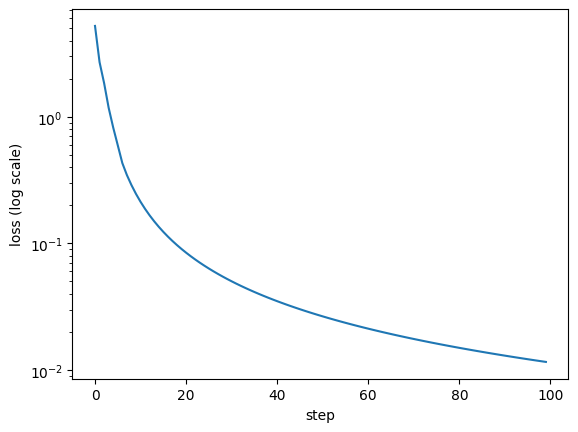

In [27]:
xs = [[2.0,3.0,-1.0], [3.0,-1.0,0.5], [0.5,1.0,1.0], [1.0,1.0,-1.0]]
ys = [1.0,-1.0,-1.0,1.0]

def train(lr=0.05, steps=100, zero_grad=True):
    random.seed(42)
    model = MLP(3,[4,4,1])
    losses = []
    for k in range(steps):

        preds = [model(x) for x in xs]
        loss = sum((yp - yt)**2 for yt, yp in zip(ys, preds))

        if zero_grad:
            for p in model.parameters():
                p.grad =0.0

        loss.backward()

        for p in model.parameters():
            p.data -=lr * p.grad
        losses.append(loss.data)
    return model, losses

model, losses = train()
for k in [0,1,9,19,49,99]:
    print(f"step {k:3d}  loss {losses[k]:.4f}")

print([round(model(x).data, 3) for x in xs])

plt.plot(losses)
plt.yscale('log'); plt.xlabel('step'); plt.ylabel('loss (log scale)')
plt.savefig("training_loss.png", dpi=150, bbox_inches="tight")


plt.show()

lr 0.001  step 1 5.1638  step 99 1.5914  preds [0.374, -0.506, -0.081, 0.693]
lr 0.05   step 1 2.7047  step 99 0.0116  preds [0.946, -0.965, -0.93, 0.951]
lr 0.5    step 1 7.9966  step 99 7.9999  preds [1.0, 1.0, 1.0, 1.0]


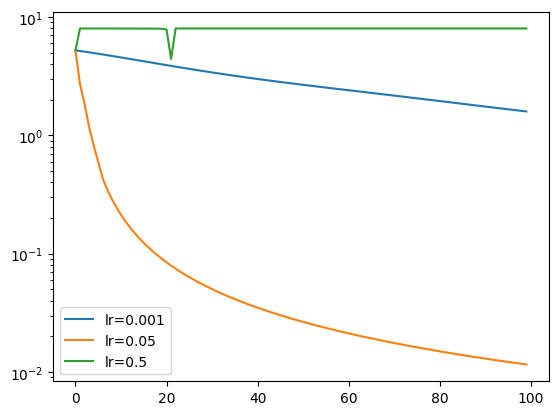

step 9 0.0001  preds [1.0, -1.0, -1.0, 1.0]
with zeroing    [2.4, 1.92, 1.536, 1.229, 0.983, 0.786, 0.629, 0.503]
without zeroing [2.4, 1.32, -0.024, -1.363, -2.43, -3.01, -2.989, -2.37]


In [28]:
#Testing
#here lr is learning rate
for lr in [0.001,0.05,0.5]:
    m, l = train(lr=lr)
    print(f"lr {lr:<6} step 1 {l[1]:.4f}  step 99 {l[99]:.4f}  preds {[round(m(x).data, 3) for x in xs]}")
    plt.plot(l, label=f"lr={lr}")
plt.yscale('log')
plt.legend()
plt.savefig("learning_rates.png", dpi=150, bbox_inches="tight")
plt.show()
# when lr is 0.001  step 1 5.1638  step 99 1.5914  preds [0.374, -0.506, -0.081, 0.693]
# lr 0.05   step 1 2.7047  step 99 0.0116  preds [0.946, -0.965, -0.93, 0.951]
# lr 0.5    step 1 7.9966  step 99 7.9999  preds [1.0, 1.0, 1.0, 1.0]


m, l = train(zero_grad=False)
print(f"step 9 {l[9]:.4f}  preds {[round(m(x).data, 3) for x in xs]}")
#bug here (had to minimise w)


for zero in [True, False]:
    w = Value(3.0)
    trace = []
    for k in range(8):
        loss = w**2
        if zero:
            w.grad = 0.0
        loss.backward()
        w.data -= 0.1 * w.grad
        trace.append(round(w.data, 3))
    print("with zeroing   " if zero else "without zeroing", trace)
# with zeroing [2.4, 1.92, 1.536, 1.229, 0.983, 0.786, 0.629, 0.503]
# without zeroing [2.4, 1.32, -0.024, -1.363, -2.43, -3.01, -2.989, -2.37]